#predict which customers are likely to stop using a *service*. (Supervised ML)

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [82]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [83]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [84]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors= 'coerce')

In [85]:
print(df.shape)
print(df.dtypes)
print(df.info())
print(df.isnull().sum())
print(df.duplicated().sum())

(7043, 21)
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object

In [86]:
print(df[df['TotalCharges'].isnull()]['TotalCharges'])

488    NaN
753    NaN
936    NaN
1082   NaN
1340   NaN
3331   NaN
3826   NaN
4380   NaN
5218   NaN
6670   NaN
6754   NaN
Name: TotalCharges, dtype: float64


In [87]:
print((df.loc[df['TotalCharges'].isnull(), 'tenure'] == 0).all())

True


#Exploratory Data Analysis(EDA)

In [88]:
print((df.loc[df['TotalCharges'].isnull(),'MonthlyCharges']>=500).all())

False


In [89]:
# Select and print specified columns for rows where 'TotalCharges' is null
columns_to_show = ['tenure', 'MonthlyCharges', 'TotalCharges']
missing_charges_df = df.loc[df['TotalCharges'].isnull(), columns_to_show]
print(missing_charges_df)

      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


In [90]:
print("Number of nulls in TotalCharges:", df['TotalCharges'].isnull().sum())

Number of nulls in TotalCharges: 11


In [91]:
#replacing those 11 missing values with zero
df = df.fillna(0)
print(df.isnull().sum().tolist())

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [92]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [93]:
df.groupby("Churn")["tenure"].mean()
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


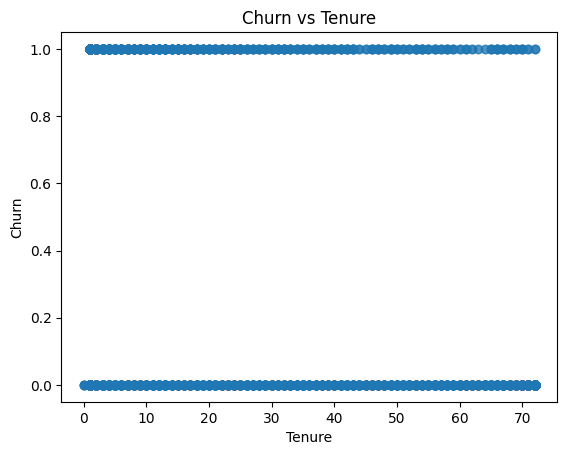

In [94]:
plt.scatter(df["tenure"],df["Churn"].map({"No":0,"Yes":1}),alpha=0.3)
plt.title("Churn vs Tenure")
plt.xlabel("Tenure")
plt.ylabel("Churn")
plt.show()

Text(0, 0.5, 'Churn')

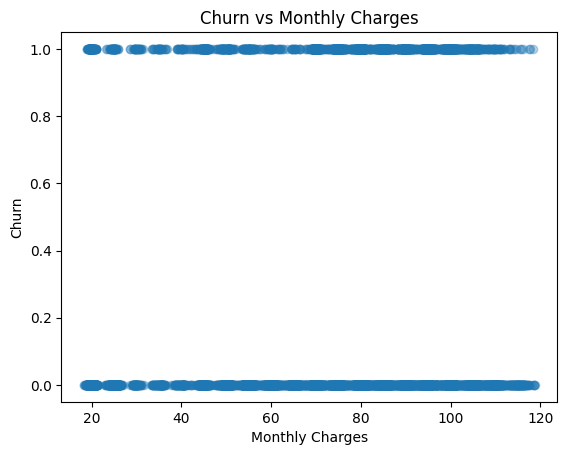

In [95]:
df.groupby("Churn")["MonthlyCharges"].mean()
df.groupby("Churn")["MonthlyCharges"].describe()
plt.scatter(df["MonthlyCharges"],df["Churn"].map({"No":0,"Yes":1}),alpha=0.3)
plt.title("Churn vs Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Churn")

In [96]:
#compare churn percentages across month-to-month, one-year, and two-year contracts.
df.groupby("Contract")["Churn"].value_counts(normalize=True)

Contract        Churn
Month-to-month  No       0.572903
                Yes      0.427097
One year        No       0.887305
                Yes      0.112695
Two year        No       0.971681
                Yes      0.028319
Name: proportion, dtype: float64

In [97]:
# Define features (X) and target (Y)
X = df.drop(columns=["customerID", "Churn"])
Y = df["Churn"]

# Split data
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y,test_size=0.2,random_state=42,stratify=Y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Y_train:", Y_train.shape)
print("Y_test:", Y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
Y_train: (5634,)
Y_test: (1409,)


In [98]:
print(X_train.dtypes)

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object


In [99]:
df["Contract"].unique()

array(['Month-to-month', 'One year', 'Two year'], dtype=object)

#preprocessing

In [100]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [101]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(),
         ["tenure", "MonthlyCharges", "TotalCharges"]),

        ("onehot", OneHotEncoder(handle_unknown="ignore"), [
            "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
            "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
            "PaperlessBilling", "PaymentMethod"
        ]),

        ("senior", "passthrough", ["SeniorCitizen"])
    ]
)

In [102]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [103]:
print(type(X_train_processed))

<class 'numpy.ndarray'>


In [104]:
print(X_train_processed.shape)
print(X_test_processed.shape)
print(X_train_processed.dtype)
print(np.isnan(X_train_processed).any())#since it is numpy array

(5634, 45)
(1409, 45)
float64
False


#Model Training

In [105]:
from sklearn.linear_model import LogisticRegression

In [106]:
lg_model = LogisticRegression()
lg_model = lg_model.fit(X_train_processed, Y_train)

In [107]:
from sklearn.metrics import classification_report
y_pred = lg_model.predict(X_test_processed)
print(classification_report(Y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [108]:
from sklearn.metrics import confusion_matrix
y_pred = lg_model.predict(X_test_processed)
cm = confusion_matrix(Y_test, y_pred)
print(cm)

[[926 109]
 [165 209]]


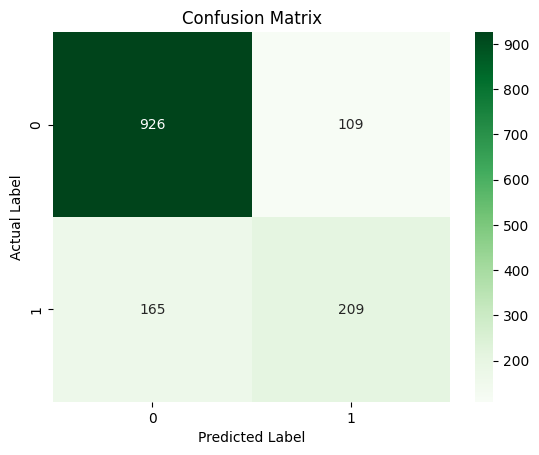

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [110]:
#balanced model
balanced_model = LogisticRegression(class_weight="balanced")
balanced_model = balanced_model.fit(X_train_processed, Y_train)
y_pred_balanced = balanced_model.predict(X_test_processed)
print(classification_report(Y_test, y_pred_balanced))

              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [111]:
y_pred_balanced = balanced_model.predict(X_test_processed)
cm_balanced = confusion_matrix(Y_test, y_pred_balanced)
print(cm_balanced)

[[747 288]
 [ 81 293]]


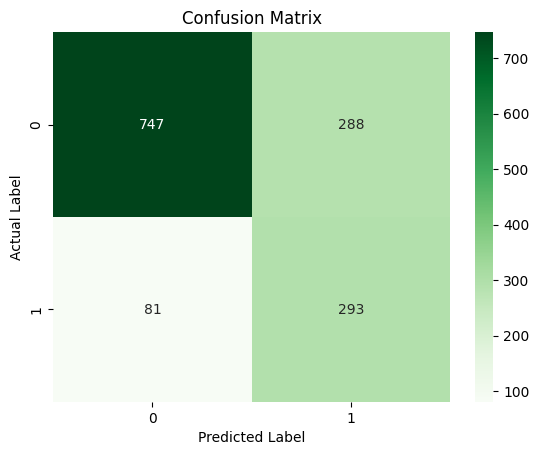

In [112]:
cm_balanced = confusion_matrix(Y_test,y_pred_balanced)
sns.heatmap(cm_balanced,annot=True,fmt="d",cmap="Greens")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [113]:
y_prob_balanced = balanced_model.predict_proba(X_test_processed)[:,1]
print(y_prob_balanced[:10])

[0.1177624  0.85183476 0.1462051  0.66067995 0.06058498 0.80542546
 0.69751079 0.29226625 0.00901689 0.6520066 ]


In [114]:
y_pred_balanced = (y_prob_balanced >= 0.3).astype(int)
print(y_pred_balanced[:10])

[0 1 0 1 0 1 1 0 0 1]


In [115]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

threshold = 0.3

# Map predictions to matching string labels ('Yes' / 'No')
y_pred_03 = np.where(y_prob_balanced >= threshold, 'Yes', 'No')

print("Confusion Matrix:")
print(confusion_matrix(Y_test, y_pred_03))

print("\nClassification Report:")
print(classification_report(Y_test, y_pred_03))

Confusion Matrix:
[[574 461]
 [ 27 347]]

Classification Report:
              precision    recall  f1-score   support

          No       0.96      0.55      0.70      1035
         Yes       0.43      0.93      0.59       374

    accuracy                           0.65      1409
   macro avg       0.69      0.74      0.64      1409
weighted avg       0.82      0.65      0.67      1409

